# 01 - Data audit and analysis-ready cohort

**Purpose.** Establish what the release actually contains, how trustworthy each modality is, and
which trials can enter each downstream analysis. Every issue found here is either corrected with a
documented rule or excluded explicitly; nothing is silently dropped.

**Dataset.** Katmah et al., *A Multimodal Gait Dataset of Brain Activity, Muscle Activity, Kinematics
and Ground Forces in Young Adults*, v1.0.0 (CC BY 4.0). 59 healthy adults, treadmill walking at
0.50, 0.75 and 1.00 m/s, one minute per speed, with EEG (DSI-24 dry, 300 Hz), surface EMG (Delsys
Trigno, 12 muscles, released as a 16 Hz mean-absolute-value envelope), full-body IMU (Xsens MVN
Awinda, 60 Hz) and a split-belt instrumented treadmill (Bertec, 1000 Hz).

The per-file checks are computed by `scripts/run_audit.py` and `scripts/build_cache.py`; this
notebook reads their tables and documents the findings.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

from mgait import config as C, io, plotting as P

P.use_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
T = C.TABLES
inv = pd.read_parquet(T / "inventory.parquet")
a_eeg = pd.read_parquet(T / "audit_eeg_trials.parquet")
a_ch = pd.read_parquet(T / "audit_eeg_channels.parquet")
a_emg = pd.read_parquet(T / "audit_emg.parquet")
a_fp = pd.read_parquet(T / "audit_fp.parquet")
a_imu = pd.read_parquet(T / "audit_imu.parquet")
sync = pd.read_parquet(T / "sync.parquet")
meta = io.load_subjects()
issues = []   # the running issue register written out at the end

## 1. Coverage

The release documentation lists missing files per modality. The inventory below confirms those
lists exactly; the practical consequence is that the four modalities are jointly available for
fewer trials than any one of them alone.

,trials,of 177
eeg,177,100.0
emg,169,95.5
fp,173,97.7
imu,170,96.0
all4,162,91.5
subjects complete at all 3 speeds (all 4 modalities),51,NaN


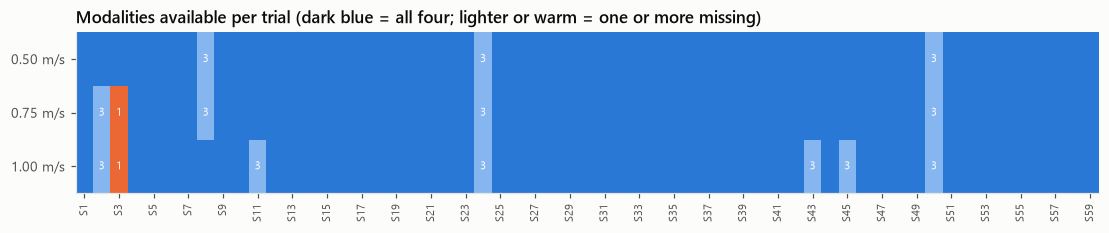

EEG  missing (0): -
EMG  missing (8): S11_1, S3_0.75, S3_1, S43_1, S50_0.5, S50_0.75, S50_1, S8_0.5
FP   missing (4): S3_0.75, S3_1, S45_1, S8_0.75
IMU  missing (7): S24_0.5, S24_0.75, S24_1, S2_0.75, S2_1, S3_0.75, S3_1


In [2]:
mods = ["eeg", "emg", "fp", "imu"]
cov = inv[mods + ["all4"]].sum().rename("trials").to_frame()
cov["of 177"] = (100 * cov["trials"] / 177).round(1)
cov.loc["subjects complete at all 3 speeds (all 4 modalities)", "trials"] = int((inv.groupby("subject")["all4"].sum() == 3).sum())
display(cov)

grid = inv.assign(code=inv[mods].sum(axis=1)).pivot(index="speed", columns="subject", values="code")
grid = grid[[f"S{i}" for i in range(1, 60)]].loc[C.SPEEDS]
fig, ax = plt.subplots(figsize=(12, 1.9))
cmap = plt.matplotlib.colors.ListedColormap(["#e34948", "#eb6834", "#eda100", "#86b6ef", "#2a78d6"])
ax.imshow(grid.to_numpy(), aspect="auto", cmap=cmap, vmin=-0.5, vmax=4.5)
ax.set_yticks(range(3), [P.SPEED_LABEL[s] for s in C.SPEEDS])
ax.set_xticks(range(0, 59, 2), grid.columns[::2], rotation=90, fontsize=7)
ax.grid(False)
ax.set_title("Modalities available per trial (dark blue = all four; lighter or warm = one or more missing)")
for (i, j), v in np.ndenumerate(grid.to_numpy()):
    if v < 4:
        ax.text(j, i, int(v), ha="center", va="center", fontsize=7, color="white")
P.save(fig, "01_coverage")
plt.show()

missing = {m: sorted(f"{r.subject}_{r.speed}" for r in inv[~inv[m]].itertuples()) for m in mods}
for m, v in missing.items():
    print(f"{m.upper():4s} missing ({len(v)}): {', '.join(v) if v else '-'}")
issues.append(("All", "Missing trials", f"{177 - int(inv['all4'].sum())} of 177 trials lack at least one modality",
               "Each analysis uses the trials available to it; multimodal analyses use the 162 complete trials", "Documented"))

## 2. Participant metadata

Three problems were found in `subject-info.csv`:

1. **Mislabelled summary rows.** The sheet ends with Average/Median/Min/Max/STD rows, and the Min and
   Max rows are swapped (Min shows the largest value). These rows are removed on load.
2. **Direct identifiers.** The sheet includes full dates of birth, although the data descriptor states
   that no personally identifiable information is included. Combined with recording dates (in the EEG
   headers), date of birth is a strong re-identification key. It is used here only to verify the age
   column and is dropped from every derived table and figure.
3. **Age is not age at testing.** The `Age` column matches date of birth only when evaluated at about
   1 January 2025 (59 of 59 records), roughly a year after the sessions (November 2023 to
   April 2024). Most participants were one year younger when tested than the sheet states. Two dates of
   birth also use a different format (backslash separators).
4. **Body mass for one participant.** The force plates measure body weight directly; this is checked
   in section 5.

,Subject,Age,BMI,Normal Speed (m/s)
59,Average,24.136,25.37,1.06
60,Median,22.000,24.37,1.03
61,Min,44.000,37.62,1.49
62,Max,20.000,18.40,0.71
63,STD,4.627,4.74,0.15


Age vs date of birth at recording: 14 of 59 agree; differences (years): {0.0: 14, 1.0: 44, 2.0: 1}
  Age column agrees with age computed at 2024-03-01: 10 of 59
  Age column agrees with age computed at 2025-01-01: 59 of 59
Reported vs recomputed BMI: max |difference| = 0.00 kg/m2


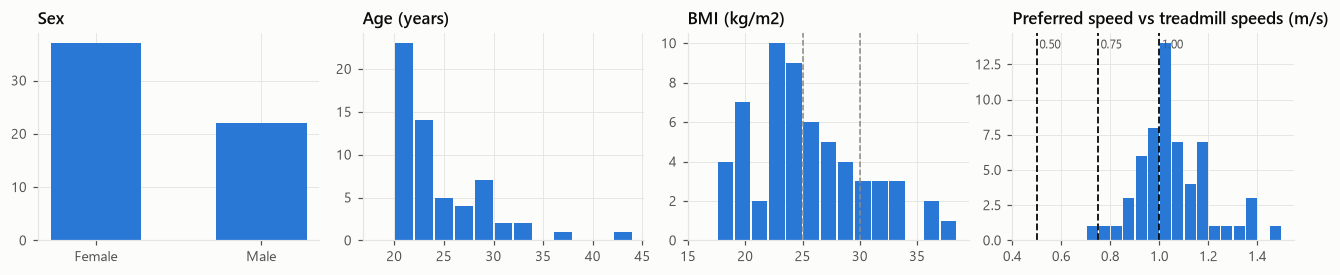

{'Normal': 32, 'Overweight': 15, 'Obese': 12}
Treadmill speeds as a fraction of preferred speed: 0.49, 0.73, 0.97 (median)
Participants whose preferred speed is below 1.00 m/s: 18 of 59


In [3]:
raw_meta = io.load_subjects_raw()
summary_rows = raw_meta[~raw_meta["Subject"].astype(str).str.fullmatch(r"S\d+")].dropna(how="all")
display(summary_rows[["Subject", "Age", "BMI", "Normal Speed (m/s)"]])

from mgait import audit
rec_dates = a_eeg.groupby("subject")["date"].first()
mc = audit.check_metadata(rec_dates)
print(f"Age vs date of birth at recording: {int((mc['age_diff'] == 0).sum())} of {mc['age_diff'].notna().sum()} agree; "
      f"differences (years): {mc['age_diff'].value_counts().sort_index().to_dict()}")
_dob = pd.to_datetime(io.load_subjects(keep_dob=True)["dob"].str.replace("\\", "/", regex=False), format="%d/%m/%Y")
for ref in ["2024-03-01", "2025-01-01"]:
    _age = np.floor((pd.Timestamp(ref) - _dob).dt.days / 365.25)
    print(f"  Age column agrees with age computed at {ref}: {int((_age == meta['age']).sum())} of {len(meta)}")
print(f"Reported vs recomputed BMI: max |difference| = {mc['bmi_abs_diff'].max():.2f} kg/m2")
issues.append(("Metadata", "Summary rows mislabelled", "Min and Max summary rows are swapped", "Summary rows removed on load", "Corrected"))
issues.append(("Metadata", "Age not at testing", "Age matches 1 Jan 2025, about a year after testing; 2 DOB formats",
               "Age used descriptively only", "Documented"))
issues.append(("Metadata", "Dates of birth released", "59 full dates of birth despite the anonymisation statement",
               "Used only to verify age; dropped from all outputs", "Mitigated"))

prof = meta.assign(bmi_class=meta["bmi_class"].astype(str))
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6))
axes[0].bar(["Female", "Male"], [(prof.sex == "F").sum(), (prof.sex == "M").sum()], color=P.CAT[0], width=0.55)
axes[0].set_title("Sex")
axes[1].hist(prof["age"], bins=range(18, 46, 2), color=P.CAT[0], rwidth=0.9)
axes[1].set_title("Age (years)")
axes[2].hist(prof["bmi"], bins=np.arange(16, 40, 1.5), color=P.CAT[0], rwidth=0.9)
for x in (25, 30):
    axes[2].axvline(x, color=P.MUTED, lw=1, ls="--")
axes[2].set_title("BMI (kg/m2)")
axes[3].hist(prof["preferred_speed"], bins=np.arange(0.7, 1.55, 0.05), color=P.CAT[0], rwidth=0.9)
axes[3].set_xlim(0.4, 1.55)
for v in (0.5, 0.75, 1.0):
    axes[3].axvline(v, color=P.INK, lw=1.2, ls="--")
    axes[3].text(v + 0.01, axes[3].get_ylim()[1] * 0.97, f"{v:.2f}", fontsize=8, color=P.INK2, va="top")
axes[3].set_title("Preferred speed vs treadmill speeds (m/s)")
fig.tight_layout()
P.save(fig, "01_participants")
plt.show()
print(prof["bmi_class"].value_counts().to_dict())
print(f"Treadmill speeds as a fraction of preferred speed: "
      f"{(0.5 / prof.preferred_speed).median():.2f}, {(0.75 / prof.preferred_speed).median():.2f}, {(1.0 / prof.preferred_speed).median():.2f} (median)")
print(f"Participants whose preferred speed is below 1.00 m/s: {(prof.preferred_speed < 1.0).sum()} of {len(prof)}")

The treadmill speeds sit at roughly half, three quarters and the whole of the participants' preferred
overground speed (median 1.03 m/s); only 18 participants prefer a speed below 1.00 m/s. The protocol
therefore samples slow to comfortable walking, and conclusions about speed effects apply to the 0.5 to
1.0 m/s range only. Relative speed (treadmill speed divided by preferred speed) is carried as a covariate.

## 3. EEG

**File integrity.** 176 of 177 files share the documented 31-column layout. `S32_1` carries a corrupted
montage header in both its CSV and EDF versions (labels such as `?`, `???`, `F6`, `C2` and a duplicated
`A2`), so its channel identities cannot be verified and it is excluded. `S8_0.5` contains a 15-second
gap in its time column (sample count is normal, three dropped ADC packets), so its effective sampling
rate is wrong; it is excluded from spectral analysis.

**CSV versus EDF.** The two formats are not interchangeable: the EDF files are the CSV data shifted by
40 samples (133 ms) and truncated to 58 s (29 two-second records). Anyone aligning the EDF files with
the other modalities would carry a 133 ms error. This analysis uses the CSV files.

In [4]:
import mne
mne.set_log_level("ERROR")
rows = []
for s, v in [("S10", "0.5"), ("S25", "0.75"), ("S40", "1"), ("S55", "0.5")]:
    raw = mne.io.read_raw_edf(C.RAW / "EEG_Data" / "EEG.edf" / f"{s}_{v}_raw.edf", preload=True)
    e = raw.get_data(picks=["EEG C3-Pz"])[0] * 1e6
    c = pd.read_csv(C.EEG_DIR / f"{s}_{v}_raw.csv", skiprows=15)["C3"].to_numpy()
    b, a = signal.butter(2, [1, 30], btype="band", fs=300)
    cf, ef = signal.filtfilt(b, a, c), signal.filtfilt(b, a, e)
    w = ef[3000:6000]
    xc = signal.correlate(cf[2000:7000], w, mode="valid")
    shift = int(np.argmax(xc)) + 2000 - 3000
    r = np.corrcoef(cf[3000 + shift:6000 + shift], w)[0, 1]
    rows.append({"trial": f"{s}_{v}", "csv_samples": len(c), "edf_samples": len(e), "edf_minus_csv_shift": -shift,
                 "r_after_shift": round(r, 4)})
display(pd.DataFrame(rows))
issues.append(("EEG", "Corrupted montage header", "S32_1 (CSV and EDF)", "Excluded", "Excluded"))
issues.append(("EEG", "15 s timing gap", "S8_0.5", "Excluded from spectral analysis", "Excluded"))
issues.append(("EEG", "EDF and CSV differ", "All EDF files: shifted 40 samples (133 ms), truncated to 58 s",
               "CSV used throughout", "Documented"))

print(a_eeg["trigger_values"].value_counts().to_string())

,trial,csv_samples,edf_samples,edf_minus_csv_shift,r_after_shift
0,S10_0.5,17960,17400,40,1.0
1,S25_0.75,17960,17400,40,1.0
2,S40_1,17960,17400,40,1.0
3,S55_0.5,17960,17400,40,1.0


trigger_values
36      164
0,36      7
0,2       5


**Trigger channel.** 164 files hold a constant trigger value; the pilot sessions (S1 to S4) show a 1 Hz
square wave or a single transition. The trigger therefore does not mark a common start event, and
alignment with the other systems has to be verified from the gait signals themselves (section 7).

**Signal quality.** After linked-ear re-referencing and a 1-40 Hz band-pass, 17 % of channel-trials have
a standard deviation above 50 uV, which is far above resting scalp EEG. Contamination is concentrated
at the frontal and frontotemporal sites (Fp1, Fp2, F7, F8) that are closest to eye and facial muscle
activity and most exposed to headset movement. Whether the remaining signal is cortical is examined
in notebook 05.

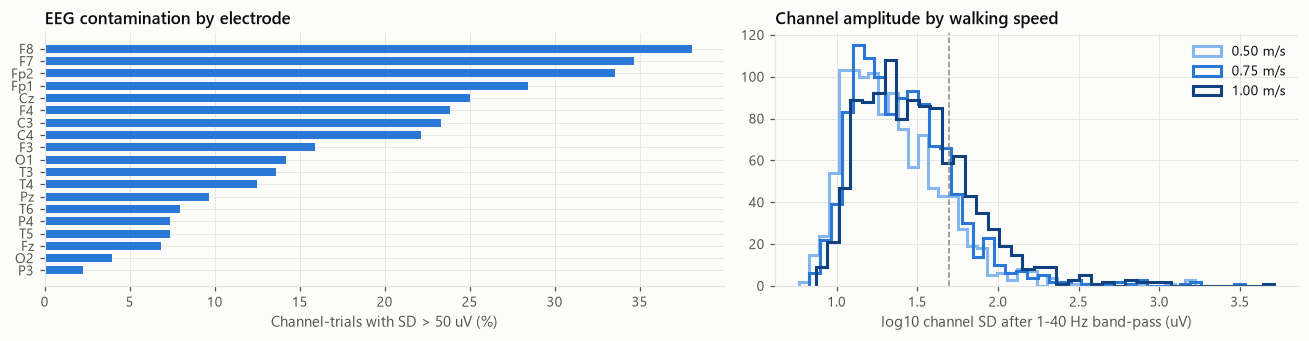

In [5]:
eeg_ok = a_ch.merge(a_eeg[["subject", "speed", "header_ok"]], on=["subject", "speed"])
bad = eeg_ok.assign(bad=eeg_ok["bp_sd_uv"] > 50).groupby("channel")["bad"].mean().reindex(C.EEG_CHANNELS)
order = bad.sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].barh(order, 100 * bad[order], color=P.CAT[0], height=0.65)
axes[0].set_xlabel("Channel-trials with SD > 50 uV (%)")
axes[0].set_title("EEG contamination by electrode")
for s in C.SPEEDS:
    d = eeg_ok[eeg_ok.speed == s]
    axes[1].hist(np.log10(d["bp_sd_uv"]), bins=40, histtype="step", lw=2, color=P.SPEED_COLORS[s], label=P.SPEED_LABEL[s])
axes[1].axvline(np.log10(50), color=P.MUTED, ls="--", lw=1)
axes[1].set_xlabel("log10 channel SD after 1-40 Hz band-pass (uV)")
axes[1].set_title("Channel amplitude by walking speed")
axes[1].legend()
fig.tight_layout()
P.save(fig, "01_eeg_quality")
plt.show()

## 4. EMG

The release contains the Delsys mean-absolute-value output at 16.05 Hz, not raw EMG. This supports
amplitude and timing analysis but rules out spectral (fatigue, conduction velocity) analysis.

For each muscle, a channel-trial is flagged as noise-dominated when its median envelope exceeds five
times the population median for that muscle. 55 of 2,028 channel-trials (2.7 %) are flagged; they cluster
within participants (for example S12 vasti, S53 calf muscles), which points to electrode placement or
skin contact rather than random dropout. Flagged channels are set to missing; the rest of the trial is kept.

Flagged channel-trials: 55 of 2028 (2.7 %)
By channel: {'R_TA': 0, 'L_TA': 0, 'R_VL': 7, 'L_VL': 10, 'R_RF': 10, 'L_RF': 0, 'R_GM': 9, 'L_GM': 5, 'R_ST': 5, 'L_ST': 5, 'R_GL': 0, 'L_GL': 4}


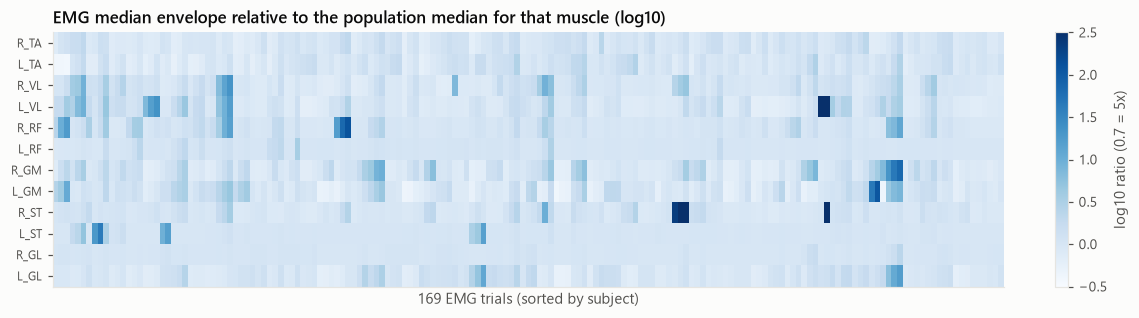

In [6]:
med = [c for c in a_emg.columns if c.endswith("_median_uv")]
ratio = a_emg[med] / a_emg[med].median()
flag = ratio > 5
print(f"Flagged channel-trials: {int(flag.values.sum())} of {flag.size} ({100 * flag.values.mean():.1f} %)")
print("By channel:", {c.replace('_median_uv', ''): int(v) for c, v in flag.sum().items()})
fig, ax = plt.subplots(figsize=(12, 3))
lr = np.log10(ratio.to_numpy().T)
im = ax.imshow(lr, aspect="auto", cmap="Blues", vmin=-0.5, vmax=2.5)
ax.set_yticks(range(len(med)), [c.replace("_median_uv", "") for c in med], fontsize=8)
ax.set_xticks([])
ax.set_xlabel(f"{len(a_emg)} EMG trials (sorted by subject)")
ax.grid(False)
ax.set_title("EMG median envelope relative to the population median for that muscle (log10)")
cb = fig.colorbar(im, ax=ax, fraction=0.02)
cb.set_label("log10 ratio (0.7 = 5x)")
P.save(fig, "01_emg_quality")
plt.show()
issues.append(("EMG", "Envelope only", "MAV at 16 Hz released instead of raw EMG", "Timing and amplitude analysis only", "Documented"))
issues.append(("EMG", "Noise-dominated channels", f"{int(flag.values.sum())} channel-trials (>5x muscle median)",
               "Channel set to missing", "Excluded"))
issues.append(("EMG", "Pilot trials longer", "S1-S3: 61-70 s instead of 60 s", "Analysed on their own timeline", "Documented"))

## 5. Force plates

Four problems were found and corrected:

* **Exported timestamps, sync and aux columns are all zero.** Time is reconstructed from the 1000 Hz
  sample index.
* **S2 files have no header row** and use a different centre-of-pressure origin. Columns are assigned
  in the documented order; COP excursion features are not compared across that convention change.
* **Unzeroed plates.** In several trials one plate reads -70 to -270 N while unloaded (S4, S5, S7, S21,
  S57). Uncorrected, this understates body weight by up to 11 % and, for S21, makes the plates look empty.
  Each plate is re-zeroed to its swing-phase level (median of its lowest quartile of samples).
* **Swapped plates for S5.** All S5 trials have the left/right centre-of-pressure sides mirrored
  relative to every other participant, and the IMU foot contacts align with the force plates only
  when the plate labels are swapped (section 7). S5 plates are relabelled.

After re-zeroing, force-plate body weight agrees with reported body mass to a median of 2.1 % across
all trials. The exception is **S24**, whose force-plate mass is 110 kg at all three speeds against
92.4 kg reported; the metadata entry is the likely error, so S24 force data are normalised to
measured body weight (as for every participant) rather than to the reported mass.

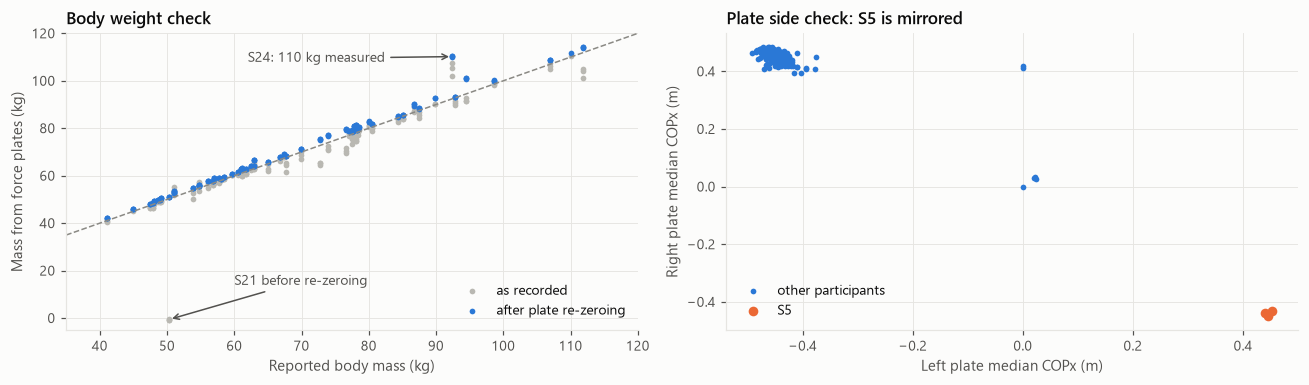

count    173.00
mean       2.67
std        2.52
min        0.43
25%        1.56
50%        2.09
75%        2.97
max       19.37


In [7]:
s2 = sync.join(meta["mass_kg"], on="subject")
s2["mass_fp"] = s2["fp_bw_n"] / C.G
s2["diff_pct"] = 100 * (s2["mass_fp"] - s2["mass_kg"]) / s2["mass_kg"]
raw_fp = a_fp.set_index(["subject", "speed"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].scatter(raw_fp["mass_reported_kg"], raw_fp["mass_from_fp_kg"], s=14, color=P.NEUTRAL, label="as recorded")
axes[0].scatter(s2["mass_kg"], s2["mass_fp"], s=14, color=P.CAT[0], label="after plate re-zeroing")
lim = [35, 120]
axes[0].plot(lim, lim, color=P.MUTED, lw=1, ls="--")
axes[0].set_xlim(lim); axes[0].set_ylim(-5, 120)
axes[0].set_xlabel("Reported body mass (kg)"); axes[0].set_ylabel("Mass from force plates (kg)")
axes[0].set_title("Body weight check")
axes[0].annotate("S24: 110 kg measured", (92.4, 110.2), xytext=(62, 108), color=P.INK2, fontsize=9,
                 arrowprops=dict(arrowstyle="->", color=P.INK2, lw=1))
axes[0].annotate("S21 before re-zeroing", (50.3, -0.6), xytext=(60, 14), color=P.INK2, fontsize=9,
                 arrowprops=dict(arrowstyle="->", color=P.INK2, lw=1))
axes[0].legend(loc="lower right")
cop = a_fp.assign(ok=a_fp["subject"].ne("S5"))
axes[1].scatter(cop.loc[cop.ok, "L_COPx_med"], cop.loc[cop.ok, "R_COPx_med"], s=14, color=P.CAT[0], label="other participants")
axes[1].scatter(cop.loc[~cop.ok, "L_COPx_med"], cop.loc[~cop.ok, "R_COPx_med"], s=40, color=P.HIGHLIGHT, label="S5")
axes[1].set_xlabel("Left plate median COPx (m)"); axes[1].set_ylabel("Right plate median COPx (m)")
axes[1].set_title("Plate side check: S5 is mirrored")
axes[1].legend(loc="lower left")
fig.tight_layout()
P.save(fig, "01_fp_checks")
plt.show()
print(s2["diff_pct"].describe().round(2).to_string())
issues.append(("Force plates", "No timestamps", "Timestamp/sync/aux columns all zero", "Time from sample index", "Corrected"))
issues.append(("Force plates", "Missing header", "S2 (3 files); different COP origin", "Standard columns assigned", "Corrected"))
issues.append(("Force plates", "Unzeroed plates", "S4, S5, S7, S21, S57 (one plate -70 to -270 N)", "Swing-phase re-zeroing", "Corrected"))
issues.append(("Force plates", "Swapped left/right plates", "S5 (3 trials)", "Relabelled (COP and IMU evidence)", "Corrected"))
issues.append(("Metadata", "Body mass inconsistent", "S24: 110 kg measured vs 92.4 kg reported", "Measured body weight used", "Corrected"))
issues.append(("Force plates", "Short recordings", "S1 (50-57 s), S4_0.75, S35_0.75", "Analysed as recorded", "Documented"))

## 6. IMU

* Pilot sessions (S1 to S3, recorded in November 2023) were exported in MVN *HD* processing mode with
  longer recordings; all later sessions use *Live* processing.
* S46_1 and all three S47 trials contain empty placeholder files (centre of mass, sensor-level
  orientation, free acceleration). The joint-angle and segment kinematics needed here are intact.
* S53_1: the right-foot stream yields no stance phases, so no strides are produced for that trial.
* The absolute vertical position of the body differs by several metres between some sessions
  (calibration origin); only relative kinematics are used.

MVN treats treadmill walking as overground progression, so the pelvis travels about 30 to 60 m per
trial. Its average horizontal speed is the suit's own estimate of walking speed, which is assessed
against the belt speed in notebook 03.

In [8]:
print(a_imu["quality"].value_counts().to_string())
print(a_imu.loc[a_imu["n_empty"] > 0, ["subject", "speed", "empty_files"]].to_string(index=False))
issues.append(("IMU", "Empty export files", "S46_1, S47 (all speeds)", "Only intact files used", "Documented"))
issues.append(("IMU", "Foot stream failure", "S53_1 right foot", "No IMU strides for that trial", "Excluded"))
issues.append(("IMU", "Processing mode differs", "S1-S3 exported in HD mode, others Live", "Pilot flag kept in analyses", "Documented"))

quality
Live    156
HD       14
subject speed                                                                                                                                                                               empty_files
    S46     1                                                                                                                Sensor_Magnetic_Field,Sensor_Orientation_-_Euler,Sensor_Orientation_-_Quat
    S47   0.5 Center_of_Mass,Ergonomic_Joint_Angles_XZY,Ergonomic_Joint_Angles_ZXY,Joint_Angles_XZY,Sensor_Free_Acceleration,Sensor_Magnetic_Field,Sensor_Orientation_-_Euler,Sensor_Orientation_-_Quat
    S47  0.75 Center_of_Mass,Ergonomic_Joint_Angles_XZY,Ergonomic_Joint_Angles_ZXY,Joint_Angles_XZY,Sensor_Free_Acceleration,Sensor_Magnetic_Field,Sensor_Orientation_-_Euler,Sensor_Orientation_-_Quat
    S47     1 Center_of_Mass,Ergonomic_Joint_Angles_XZY,Ergonomic_Joint_Angles_ZXY,Joint_Angles_XZY,Sensor_Free_Acceleration,Sensor_Magnetic_Field,Sensor_Orientation_-_

## 7. Cross-modal synchronisation

EEG, EMG and IMU share a wireless trigger network; the treadmill could not be hardware-triggered and
was started by hand. Synchronisation was therefore verified empirically: for every trial with both
force-plate and IMU data, foot-contact series from the two independent systems were cross-correlated
over lags of up to 4 s.

Because gait is periodic, a cross-correlation always has peaks one stride apart; the global maximum is
still unique because stride times vary from stride to stride. The swapped-label check for S5 uses the
same machinery: the S5 contacts align at 0.0 s only when the plate labels are exchanged.

,trials
status,
aligned (|lag| <= 0.1 s),157
not aligned (> 0.3 s),6
offset 0.1-0.3 s,5


,subject,speed,final_lag_s,final_peak_r
74,S25,1,-3.75,0.710
6,S3,0.5,-0.64,0.906
1,S1,0.75,-0.45,0.850
3,S2,0.5,-0.15,0.941
141,S48,0.5,-0.14,0.905
143,S48,1,-0.13,0.962
58,S20,0.75,0.17,0.680
59,S20,1,0.20,0.651
10,S4,0.75,2.17,0.861
0,S1,0.5,3.37,0.847


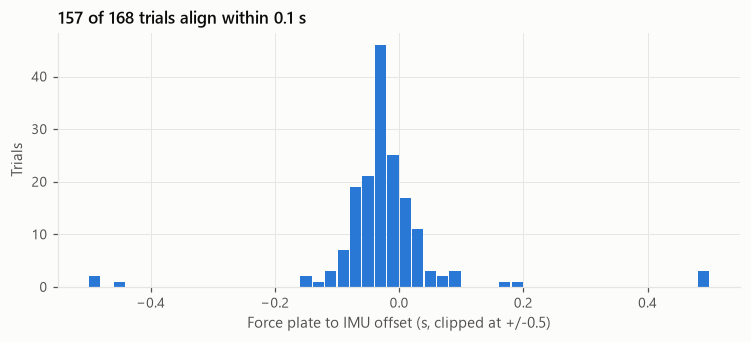

In [9]:
sv = sync.dropna(subset=["final_lag_s"]).copy()
sv["pilot"] = sv["subject"].isin(C.PILOT_SUBJECTS)
sv["status"] = np.select([sv["final_lag_s"].abs() <= 0.1, sv["final_lag_s"].abs() <= 0.3],
                         ["aligned (|lag| <= 0.1 s)", "offset 0.1-0.3 s"], "not aligned (> 0.3 s)")
display(sv["status"].value_counts().to_frame("trials"))
display(sv.loc[sv["final_lag_s"].abs() > 0.1, ["subject", "speed", "final_lag_s", "final_peak_r"]].sort_values("final_lag_s"))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sv["final_lag_s"].clip(-0.5, 0.5), bins=np.arange(-0.5, 0.52, 0.02), color=P.CAT[0], rwidth=0.9)
ax.set_xlabel("Force plate to IMU offset (s, clipped at +/-0.5)")
ax.set_ylabel("Trials")
ax.set_title(f"{(sv['final_lag_s'].abs() <= 0.1).sum()} of {len(sv)} trials align within 0.1 s")
P.save(fig, "01_sync")
plt.show()
n_bad = int((sv["final_lag_s"].abs() > 0.1).sum())
issues.append(("Synchronisation", "Treadmill started by hand", f"{n_bad} of {len(sv)} trials offset by more than 0.1 s",
               "Force-plate timing used only within force-plate analyses for those trials; EMG/EEG use IMU events",
               "Mitigated"))

Most trials align to within the 10 ms resolution of the search (median offset -0.02 s). The offsets that
remain are concentrated in the pilot sessions (S1, S3, S4) and a few later trials, consistent with the
manual treadmill start described in the protocol. Two consequences follow:

* Event-level comparisons between force plates and IMU (notebook 03) use only trials aligned within 0.1 s.
* EMG and EEG are segmented with IMU gait events, which share their trigger network. The EMG timing check
  in notebook 04 (calf muscles peaking in late stance, tibialis anterior at heel strike) confirms that
  alignment independently.

## 8. Issue register and analysis cohorts

In [10]:
reg = pd.DataFrame(issues, columns=["Modality", "Issue", "Scope", "Treatment", "Status"])
reg.to_csv(C.TABLES / "data_issues.csv", index=False)
print(f"{len(reg)} issues registered: {reg['Status'].value_counts().to_dict()}")
display(reg)

20 issues registered: {'Documented': 8, 'Corrected': 6, 'Excluded': 4, 'Mitigated': 2}


,Modality,Issue,Scope,Treatment,Status
0,All,Missing trials,15 of 177 trials lack at least one modality,Each analysis uses the trials available to it;...,Documented
1,Metadata,Summary rows mislabelled,Min and Max summary rows are swapped,Summary rows removed on load,Corrected
2,Metadata,Age not at testing,"Age matches 1 Jan 2025, about a year after tes...",Age used descriptively only,Documented
3,Metadata,Dates of birth released,59 full dates of birth despite the anonymisati...,Used only to verify age; dropped from all outputs,Mitigated
4,EEG,Corrupted montage header,S32_1 (CSV and EDF),Excluded,Excluded
5,EEG,15 s timing gap,S8_0.5,Excluded from spectral analysis,Excluded
6,EEG,EDF and CSV differ,"All EDF files: shifted 40 samples (133 ms), tr...",CSV used throughout,Documented
7,EMG,Envelope only,MAV at 16 Hz released instead of raw EMG,Timing and amplitude analysis only,Documented
8,EMG,Noise-dominated channels,55 channel-trials (>5x muscle median),Channel set to missing,Excluded
9,EMG,Pilot trials longer,S1-S3: 61-70 s instead of 60 s,Analysed on their own timeline,Documented


In [11]:
ft = pd.read_parquet(C.CACHE / "fp_strides.parquet")
it = pd.read_parquet(C.CACHE / "imu_strides.parquet")
et = pd.read_parquet(C.CACHE / "emg_strides.parquet")
ec = pd.read_parquet(C.CACHE / "eeg_channels.parquet")
eeg_trials = ec[["subject", "speed"]].drop_duplicates()
eeg_trials = eeg_trials[~((eeg_trials.subject == "S8") & (eeg_trials.speed == "0.5"))]
cohort = pd.DataFrame({
    "trials": [ft.groupby(["subject", "speed"]).ngroups, it.groupby(["subject", "speed"]).ngroups,
               et.groupby(["subject", "speed"]).ngroups, len(eeg_trials), int((sv["final_lag_s"].abs() <= 0.1).sum())],
    "participants": [ft.subject.nunique(), it.subject.nunique(), et.subject.nunique(), eeg_trials.subject.nunique(),
                     sv.loc[sv["final_lag_s"].abs() <= 0.1, "subject"].nunique()],
    "strides": [int(ft.qc_ok.sum()), int(it.qc_ok.sum()), len(et), np.nan, np.nan],
}, index=["Force-plate gait analysis", "IMU kinematics", "EMG gait cycles", "EEG spectral analysis",
          "Force plate vs IMU agreement"])
cohort.to_csv(C.TABLES / "cohorts.csv")
display(cohort)

,trials,participants,strides
Force-plate gait analysis,173,59,15574.0
IMU kinematics,169,58,14964.0
EMG gait cycles,168,58,14882.0
EEG spectral analysis,175,59,NaN
Force plate vs IMU agreement,157,55,NaN


**Summary.** The release is usable, but not as published: the register above lists the issues that
affect metadata, timing, calibration and channel labels. The corrections above recover all 173 force-plate trials (including
the apparently empty S21 and the swapped S5), and every exclusion is limited to the specific channel or
trial affected. The analysis-ready cohorts are fixed here and used unchanged by the remaining notebooks.